# Q2

In [1]:
# Q2
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [2]:

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

norm = transforms.Normalize((0.1307,), (0.3081,))

train_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(), norm])
eval_tf = transforms.Compose([transforms.ToTensor(), norm])


Using device: cpu


In [3]:

train_set = torchvision.datasets.MNIST('./data1', train=True, download=False, transform=train_tf)
train_eval_set = torchvision.datasets.MNIST('./data1', train=True, download=False, transform=eval_tf)
test_set = torchvision.datasets.MNIST('./data1', train=False, download=True, transform=eval_tf)

trainloader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)
train_eval_loader = torch.utils.data.DataLoader(train_eval_set, batch_size=1000, shuffle=False)
testloader = torch.utils.data.DataLoader(test_set, batch_size=1000, shuffle=False)


In [4]:


class LeNet5(nn.Module):  # architecture unchanged (faithful LeNet-5)
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5, padding=2), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(),
            nn.Linear(84, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

In [5]:

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2))

        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))
        # FIX 3: small hidden FC layer + dropout gives the head more capacity
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))



In [6]:

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * y.size(0)
            pred = out.argmax(1)
            correct += (pred == y).sum().item()
            total += y.size(0)
            all_preds.append(pred.cpu())
            all_labels.append(y.cpu())
    return (total_loss / total, 100 * correct / total,
            torch.cat(all_preds), torch.cat(all_labels))


def train_model(model, epochs=10, max_lr=3e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=max_lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=max_lr, epochs=epochs, steps_per_epoch=len(trainloader))
    hist = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    for ep in range(epochs):
        model.train()
        for x, y in trainloader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            scheduler.step()          # step per batch for OneCycleLR

        tr_loss, tr_acc, _, _ = evaluate(model, train_eval_loader, criterion)
        te_loss, te_acc, _, _ = evaluate(model, testloader, criterion)
        hist["train_loss"].append(tr_loss); hist["train_acc"].append(tr_acc)
        hist["test_loss"].append(te_loss);  hist["test_acc"].append(te_acc)
        print(f"Epoch {ep+1}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.2f}% "
              f"| test loss {te_loss:.4f} acc {te_acc:.2f}%")
    return hist


Epoch 1/10 | train loss 0.1566 acc 95.73% | test loss 0.1409 acc 96.20%
Epoch 2/10 | train loss 0.0808 acc 97.53% | test loss 0.0761 acc 97.77%
Epoch 3/10 | train loss 0.0787 acc 97.61% | test loss 0.0655 acc 98.03%
Epoch 4/10 | train loss 0.0632 acc 98.07% | test loss 0.0581 acc 98.28%
Epoch 5/10 | train loss 0.0621 acc 98.05% | test loss 0.0546 acc 98.13%
Epoch 6/10 | train loss 0.0488 acc 98.47% | test loss 0.0501 acc 98.45%
Epoch 7/10 | train loss 0.0348 acc 98.94% | test loss 0.0390 acc 98.85%
Epoch 8/10 | train loss 0.0300 acc 99.11% | test loss 0.0340 acc 98.89%
Epoch 9/10 | train loss 0.0241 acc 99.28% | test loss 0.0289 acc 99.12%
Epoch 10/10 | train loss 0.0234 acc 99.32% | test loss 0.0277 acc 99.16%


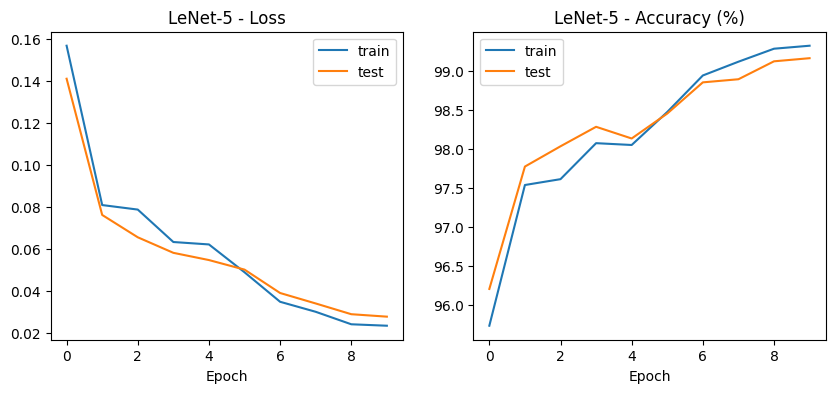

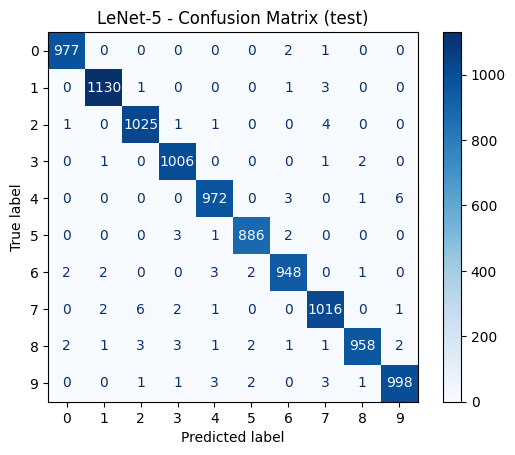

In [7]:


def plot_history(hist, name):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["test_loss"], label="test")
    ax[0].set_title(f"{name} - Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(hist["train_acc"], label="train"); ax[1].plot(hist["test_acc"], label="test")
    ax[1].set_title(f"{name} - Accuracy (%)"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.show()


def show_confusion(model, name):
    _, _, preds, labels = evaluate(model, testloader, nn.CrossEntropyLoss())
    cm = confusion_matrix(labels, preds)
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(cmap="Blues")
    plt.title(f"{name} - Confusion Matrix (test)")
    plt.show()


torch.manual_seed(SEED)
lenet = LeNet5()
lenet_hist = train_model(lenet, epochs=10)
plot_history(lenet_hist, "LeNet-5")
show_confusion(lenet, "LeNet-5")


Epoch 1/10 | train loss 0.0540 acc 98.29% | test loss 0.0446 acc 98.47%
Epoch 2/10 | train loss 0.0454 acc 98.54% | test loss 0.0382 acc 98.63%
Epoch 3/10 | train loss 0.0336 acc 98.95% | test loss 0.0321 acc 98.93%
Epoch 4/10 | train loss 0.0325 acc 98.98% | test loss 0.0314 acc 98.96%
Epoch 5/10 | train loss 0.0196 acc 99.37% | test loss 0.0182 acc 99.33%
Epoch 6/10 | train loss 0.0188 acc 99.43% | test loss 0.0195 acc 99.37%
Epoch 7/10 | train loss 0.0137 acc 99.58% | test loss 0.0179 acc 99.47%
Epoch 8/10 | train loss 0.0110 acc 99.68% | test loss 0.0135 acc 99.56%
Epoch 9/10 | train loss 0.0100 acc 99.71% | test loss 0.0120 acc 99.65%
Epoch 10/10 | train loss 0.0091 acc 99.72% | test loss 0.0117 acc 99.64%


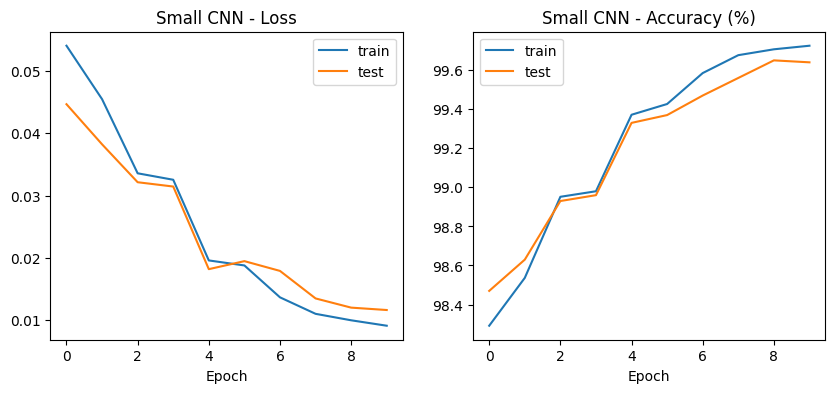

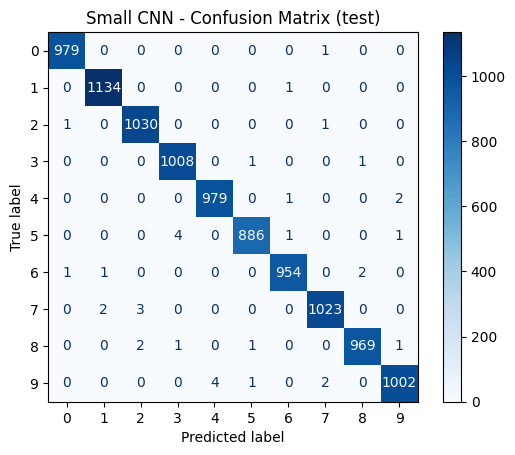

LeNet-5   : train 99.32%, test 99.16%
Small CNN : train 99.72%, test 99.64%


In [8]:

torch.manual_seed(SEED)
cnn = SmallCNN()
cnn_hist = train_model(cnn, epochs=10)
plot_history(cnn_hist, "Small CNN")
show_confusion(cnn, "Small CNN")

print(f"LeNet-5   : train {lenet_hist['train_acc'][-1]:.2f}%, test {lenet_hist['test_acc'][-1]:.2f}%")
print(f"Small CNN : train {cnn_hist['train_acc'][-1]:.2f}%, test {cnn_hist['test_acc'][-1]:.2f}%")

(a) LeNet-5 after 10 epochs
LeNet5 has two 5×5 convolutions (6 and 16 filters) with Tanh and average pooling, followed by 120-84-10 fully connected layers, about 61.7k parameters in total. I trained it for 10 epochs with AdamW, a OneCycleLR schedule (max lr 3e-3), batch size 64 and random affine augmentation. Accuracy was measured on unaugmented images.
Training accuracy: 99.32% (loss 0.0234)
Test accuracy: 99.16% (loss 0.0277)

(b) Small CNN under the same conditions
The Small CNN has three blocks of 3×3 conv, BatchNorm, ReLU and max-pool (32, 64, 128 filters), then a 128-unit hidden layer with Dropout(0.3) and an output layer. It has about 242k parameters and was trained with the same settings.
Training accuracy: 99.72% (loss 0.0091)
Test accuracy: 99.64% (loss 0.0117)

(c) Curves and confusion matrices
LeNet5 Training and test loss both fall steadily (0.157 to 0.023 and 0.141 to 0.028) and test accuracy rises from 96.2% to 99.16%. There is a small dip at epoch 5 and most of the gain comes in epochs 6-9 as the learning rate decays. The train-test gap is only about 0.16 points so there is no real overfitting and the model was still improving at epoch 10.

Small CNN It starts much stronger at 98.47% test accuracy after epoch 1 (LeNet: 96.2%). It stalls around 99% in epochs 3-4 jumps to 99.33% at epoch 5 and ends at 99.64%. Test loss keeps falling to 0.0117 at epoch 10 and the gap is just 0.08 points. so it generalises very well.